# 02 · Modelo base: regresión logística

**Proyecto:** Alerta temprana de deserción · SENA
**Autor:** Andrés · **Revisor:** David

**Objetivo:** entender cómo se comporta el modelo final antes de llevarlo a la API. Buscamos:

1. Comprobar que el cuaderno reproduce exactamente las métricas de `reports/metricas_modelo_base.json`.
2. Ver el compromiso entre recall y precisión, y dónde cae el umbral elegido (0.461).
3. Traducir las métricas a aprendices: cuántos desertores se detectan y cuántas alertas son falsas.
4. Comparar el rendimiento por modalidad.
5. Identificar qué variables empujan el riesgo (coeficientes).

El cuaderno **no entrena un modelo distinto**: reutiliza `construir_pipeline` y las funciones de `modelado.py`, así que lo que se ve aquí es lo que produce `dvc repro train`. La decisión del modelo está en el [ADR 0002](../docs/decisiones/0002-eleccion-modelo.md).

## 1. Configuración

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve

from desercion.modelado import RUTA_TEST, RUTA_TRAIN, separar_x_y, tipos_de_columnas
from desercion.train_model import calcular_metricas, cargar_config, construir_pipeline

# Raíz del repositorio: funciona tanto si el cuaderno se abre desde notebooks/ como desde la raíz.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUTA_METRICAS = RAIZ / "reports" / "metricas_modelo_base.json"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

c:\Users\ACER\Documents\Especilaizaicon\proyecto2\desercion-sena\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Datos y modelo

Las rutas de `modelado.py` son relativas a la raíz del repositorio, por eso se anteponen con `RAIZ`. El umbral **no se recalcula**: se lee del JSON que escribió la etapa `train`, para usar exactamente el mismo.

In [2]:
train = pd.read_parquet(RAIZ / RUTA_TRAIN)
test = pd.read_parquet(RAIZ / RUTA_TEST)
x_train, y_train = separar_x_y(train)
x_test, y_test = separar_x_y(test)
numericas, categoricas = tipos_de_columnas(x_train)

config = cargar_config(RAIZ / "config" / "model" / "logistic.yaml")
metricas_json = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
UMBRAL = metricas_json["umbral"]

pipeline = construir_pipeline(numericas, categoricas, config)
pipeline.fit(x_train, y_train)
probabilidad = pipeline.predict_proba(x_test)[:, 1]

print(f"Train: {len(x_train):,} · Test: {len(x_test):,} · Variables: {x_train.shape[1]}")
print(f"Umbral (out-of-fold, desde train): {UMBRAL:.3f}")

Train: 7,974 · Test: 1,544 · Variables: 39
Umbral (out-of-fold, desde train): 0.461


## 3. ¿Reproduce el pipeline?

Si el cuaderno y la etapa `train` usan los mismos datos, código y config, las métricas deben coincidir. Si esta celda falla, el cuaderno está desactualizado respecto al pipeline (o faltó `dvc repro`).

In [3]:
metricas = calcular_metricas(y_test, probabilidad, UMBRAL)
comparacion = pd.DataFrame(
    {"cuaderno": metricas, "pipeline": {k: metricas_json[k] for k in metricas}}
).round(4)
display(comparacion)

for nombre, valor in metricas.items():
    assert np.isclose(valor, metricas_json[nombre]), f"{nombre} no coincide con el pipeline"
print("✅ Métricas idénticas a reports/metricas_modelo_base.json")

,cuaderno,pipeline
recall,0.6856,0.6856
precision,0.4815,0.4815
f1,0.5657,0.5657
roc_auc,0.7346,0.7346
pr_auc,0.5756,0.5756


✅ Métricas idénticas a reports/metricas_modelo_base.json


## 4. Compromiso recall–precisión

La curva muestra todos los umbrales posibles. Bajar el umbral detecta más desertores (recall) a cambio de más falsas alarmas (menos precisión). La línea horizontal es la tasa de deserción en test: la precisión de alertar al azar.

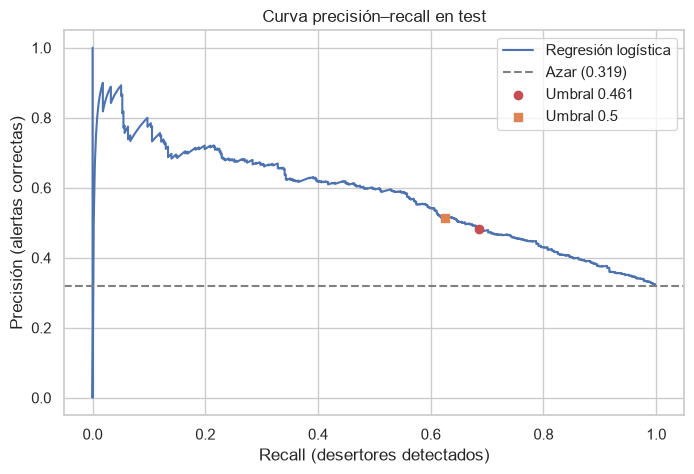

In [4]:
precision, recall, umbrales = precision_recall_curve(y_test, probabilidad)
fig, ax = plt.subplots()
ax.plot(recall, precision, label="Regresión logística")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Azar ({y_test.mean():.3f})")
ax.scatter(metricas["recall"], metricas["precision"], color="C3", zorder=3,
           label=f"Umbral {UMBRAL:.3f}")
idx_05 = np.argmin(np.abs(umbrales - 0.5))
ax.scatter(recall[idx_05], precision[idx_05], color="C1", marker="s", zorder=3, label="Umbral 0.5")
ax.set(xlabel="Recall (desertores detectados)", ylabel="Precisión (alertas correctas)",
       title="Curva precisión–recall en test")
ax.legend()
plt.show()

## 5. En aprendices: matriz de confusión

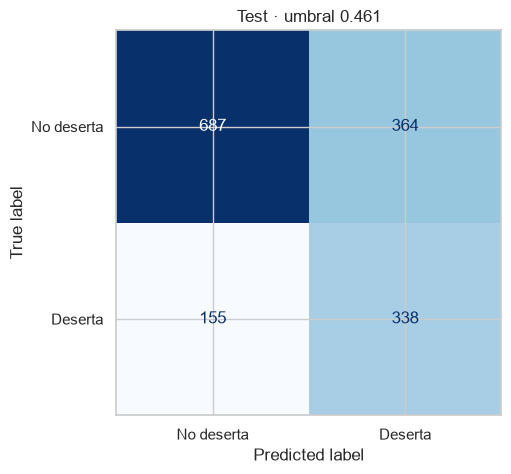

Desertores detectados: 338 de 493
Desertores sin alerta: 155
Alertas falsas: 364 de 702 alertas


In [5]:
alerta = (probabilidad >= UMBRAL).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, alerta),
                       display_labels=["No deserta", "Deserta"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Test · umbral {UMBRAL:.3f}")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, alerta).ravel()
print(f"Desertores detectados: {tp} de {tp + fn}")
print(f"Desertores sin alerta: {fn}")
print(f"Alertas falsas: {fp} de {tp + fp} alertas")

## 6. Rendimiento por modalidad

Mismo umbral para todas las modalidades. Una brecha grande en recall significa que el modelo protege peor a un grupo.

In [6]:
por_modalidad = (
    pd.DataFrame({"modalidad": x_test["modalidad"], "real": y_test, "alerta": alerta})
    .groupby("modalidad")
    .apply(lambda g: pd.Series({
        "aprendices": len(g),
        "desertores": int(g["real"].sum()),
        "recall": (g["alerta"] & g["real"]).sum() / g["real"].sum(),
        "precision": (g["alerta"] & g["real"]).sum() / g["alerta"].sum(),
        "tasa_alerta": g["alerta"].mean(),
    }), include_groups=False)
    .round(3)
)
display(por_modalidad)

,aprendices,desertores,recall,precision,tasa_alerta
modalidad,,,,,
mixta,307.0,90.0,0.756,0.486,0.456
presencial,463.0,101.0,0.525,0.434,0.263
virtual,774.0,302.0,0.719,0.493,0.568


## 7. ¿Qué empuja el riesgo? Coeficientes

Las variables numéricas están escaladas, así que sus coeficientes son comparables entre sí: un coeficiente positivo aumenta la probabilidad de desertar. Las categóricas se leen respecto a las demás categorías de la misma variable. Es asociación, no causalidad.

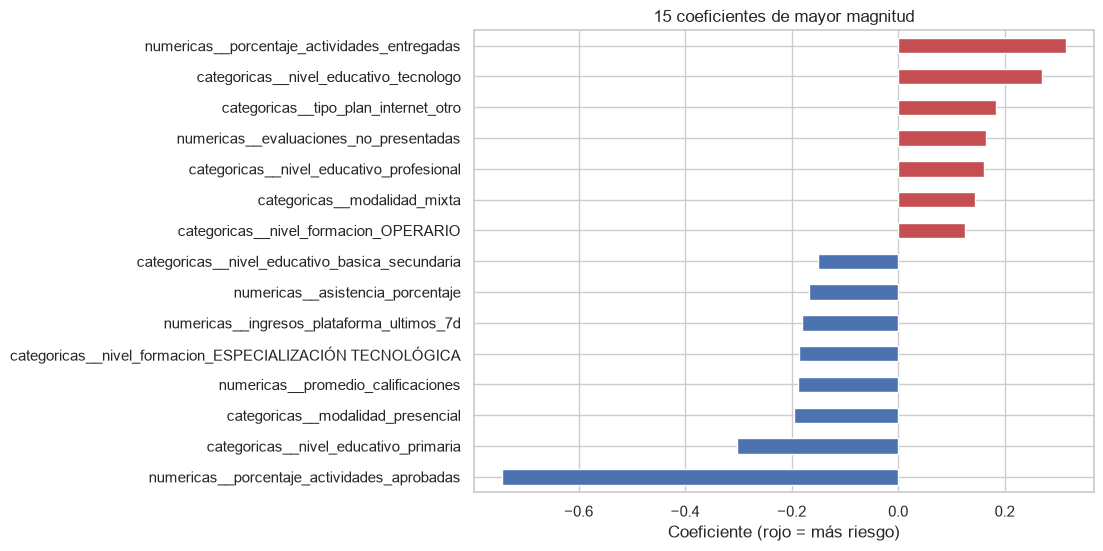

In [7]:
nombres = pipeline.named_steps["preprocesamiento"].get_feature_names_out()
coeficientes = pd.Series(pipeline.named_steps["modelo"].coef_[0], index=nombres)
top = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top.sort_values().plot.barh(ax=ax, color=np.where(top.sort_values() > 0, "C3", "C0"))
ax.set(xlabel="Coeficiente (rojo = más riesgo)", title="15 coeficientes de mayor magnitud")
plt.show()

In [8]:
x_train[["porcentaje_actividades_entregadas", "porcentaje_actividades_aprobadas", "tasa_aprobacion_entregas"]].corr().round(2)

,porcentaje_actividades_entregadas,porcentaje_actividades_aprobadas,tasa_aprobacion_entregas
porcentaje_actividades_entregadas,1.00,0.95,0.40
porcentaje_actividades_aprobadas,0.95,1.00,0.66
tasa_aprobacion_entregas,0.40,0.66,1.00


In [9]:
# Tasa de deserción por nivel educativo previo y por nivel del programa
tasas = {
    col: train.groupby(col)["deserto"].agg(aprendices="size", tasa_desercion="mean")
    .sort_values("tasa_desercion", ascending=False).round(3)
    for col in ["nivel_educativo", "nivel_formacion"]
}
display(tasas["nivel_educativo"], tasas["nivel_formacion"])

# Cruce: qué programas cursa cada nivel educativo (requisitos de ingreso)
pd.crosstab(train["nivel_educativo"], train["nivel_formacion"])

,aprendices,tasa_desercion
nivel_educativo,,
tecnologo,803,0.342
primaria,434,0.336
tecnico,1877,0.311
profesional,290,0.307
bachillerato,2808,0.302
basica_secundaria,1762,0.299


,aprendices,tasa_desercion
nivel_formacion,,
OPERARIO,521,0.370
AUXILIAR,608,0.326
TECNÓLOGO,3034,0.314
ESPECIALIZACIÓN TECNOLÓGICA,487,0.306
TÉCNICO,3324,0.294


nivel_formacion,AUXILIAR,ESPECIALIZACIÓN TECNOLÓGICA,OPERARIO,TECNÓLOGO,TÉCNICO
nivel_educativo,,,,,
bachillerato,131,0,103,1221,1353
basica_secundaria,253,0,208,0,1301
primaria,224,0,210,0,0
profesional,0,290,0,0,0
tecnico,0,0,0,1207,670
tecnologo,0,197,0,606,0


El nivel educativo previo y el nivel del programa están entrelazados por los requisitos de ingreso: los aprendices con primaria solo cursan programas de auxiliar u operario, y los profesionales solo especializaciones tecnológicas. Por eso sus coeficientes se compensan: los aprendices con primaria desertan más que el promedio (33.6 %) aunque su coeficiente sea negativo, porque ese riesgo ya lo recoge el nivel del programa (operario 37.0 %, auxiliar 32.6 %).

## 8. Conclusiones

1. **Reproducibilidad.** Las métricas obtenidas en este cuaderno coinciden, hasta el cuarto decimal, con las registradas por la etapa `train` en `reports/metricas_modelo_base.json` (recall 0.6856, precisión 0.4815, F1 0.5657, ROC-AUC 0.7346, PR-AUC 0.5756). El análisis corresponde, por tanto, al mismo modelo que produce `dvc repro train`, y la verificación automática de la sección 3 impide que el cuaderno quede desactualizado sin advertencia.

2. **Umbral de decisión.** El umbral de 0.461, elegido con predicciones out-of-fold en train sin intervención del conjunto de test, desplaza el compromiso hacia la detección: frente al umbral de 0.5, el recall aumenta de 0.623 a 0.686 y la precisión disminuye de 0.512 a 0.481. Las métricas independientes del umbral (ROC-AUC y PR-AUC) no varían, lo que confirma que el cambio afecta únicamente al punto de corte y no al modelo. El recall en test (0.686) es ligeramente inferior al alcanzado en validación cruzada (0.701), diferencia compatible con el cambio entre cohortes y que justifica el monitoreo del modelo.

3. **Impacto operativo.** Con el umbral elegido, el modelo emite 702 alertas en test y detecta 338 de los 493 desertores (68.6 %). Una selección aleatoria del mismo número de aprendices identificaría aproximadamente 224 desertores; el modelo detecta unos 114 adicionales con el mismo esfuerzo de contacto. Como contrapartida, 364 alertas (52 %) corresponden a aprendices que no desertan, por lo que las acciones de apoyo asociadas deben ser de bajo costo y beneficiosas para cualquier aprendiz, y no de carácter sancionatorio. Los 155 desertores sin alerta reflejan el límite de la información disponible en los datos.

4. **Equidad entre modalidades.** El recall es de 0.756 en mixta, 0.719 en virtual y 0.525 en presencial. La precisión es similar en las tres modalidades (0.43–0.49), de modo que la brecha no se debe a un mayor error de las alertas, sino a que el modelo alerta proporcionalmente menos en presencial: 1.21 alertas por cada desertor real, frente a 1.46 en virtual y 1.56 en mixta. El coeficiente negativo de `modalidad_presencial` (−0.19) contribuye a este efecto, al reducir el riesgo estimado de todo aprendiz presencial. El análisis de las causas y la evaluación de posibles ajustes, como umbrales diferenciados elegidos con validación cruzada, se abordan en el cuaderno 04.

5. **Variables asociadas al riesgo.** El desempeño académico es la señal dominante: el porcentaje de actividades aprobadas presenta el coeficiente de mayor magnitud (−0.74), seguido del promedio de calificaciones y las evaluaciones no presentadas. La actividad del aprendiz (asistencia e ingresos a la plataforma en los últimos 7 días) también se asocia con menor riesgo. Algunos coeficientes no deben interpretarse de forma aislada porque corresponden a variables entrelazadas. El signo positivo de `porcentaje_actividades_entregadas` se explica por su correlación de 0.95 con el porcentaje de actividades aprobadas: ambos coeficientes se reparten un mismo efecto. De forma análoga, el nivel educativo previo y el nivel del programa están ligados por los requisitos de ingreso (los aprendices con primaria solo cursan programas de auxiliar u operario, y los profesionales solo especializaciones tecnológicas), por lo que sus coeficientes se compensan: los aprendices con primaria presentan una tasa de deserción superior al promedio (33.6 %), aunque su coeficiente sea negativo, porque ese riesgo ya lo recoge el nivel del programa. Las tasas observadas indican mayor deserción en los programas de operario (37.0 %) y auxiliar (32.6 %) y entre aprendices con formación previa de tecnólogo (34.2 %). Los coeficientes expresan asociación y no causalidad.


6. **Implicaciones.** Las variables de desempeño y actividad son observables en la semana 4 y permiten orientar intervenciones oportunas; las variables de perfil, como el nivel educativo, contribuyen a estimar el riesgo pero no sugieren acciones directas. Como mejora futura, la eliminación de una de las dos variables de actividades altamente correlacionadas facilitaría la interpretación de los coeficientes, cambio que deberá validarse con validación cruzada antes de incorporarse al modelo.